### Innitialisation

In [2]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from functools import reduce
import seaborn as sns
from pyspark.sql import SparkSession
from itertools import combinations
import numpy as np
import pandas as pd

spark = (
    SparkSession.builder
    .getOrCreate()
)

### Nettoyage du fichier

In [3]:
df_raw = spark.read.option("multiLine", True).json("../data/personnages_fr.json")
#On retire les premier label qui entoure les personnages
df_perso = (
    df_raw.select(F.explode("personnages").alias("p")).select("p.*")
)


#On retire les label EN et JP et doublons et ce qui nous intéresse pas
df_perso = df_perso.drop("nom_en", "nom_jp", "stats_lvl_100", "description")

def clean_slot(slot):
    s = F.col(f"competences.{slot}")
    return s.withField(
        "niveaux",
        F.transform(s["niveaux"], lambda n: n.dropFields("nom_jp", "description_jp"))
    )

slots = ["competence_1", "competence_2", "competence_3", "incarnation"]

df_perso = df_perso.withColumn(
    "competences",
    F.struct(*[clean_slot(s).alias(s) for s in slots])
)

print("Nettoyage : \n- Des labes non concerné par des personnages\n- Des partie EN et JP \n- Des description des personnages ")

Nettoyage : 
- Des labes non concerné par des personnages
- Des partie EN et JP 
- Des description des personnages 


### Transformation

In [4]:
slots = ["competence_1", "competence_2", "competence_3", "incarnation"]

def niveaux_du_slot(slot):
    return (
        df_perso
        .select(
            F.col("id").alias("perso_id"),
            F.lit(slot).alias("slot"),
            F.col(f"competences.{slot}.nom").alias("competence_nom"),
            F.col(f"competences.{slot}.type").alias("competence_type"),
            F.explode(f"competences.{slot}.niveaux").alias("n"),
        )
        .select("perso_id", "slot", "competence_nom", "competence_type", "n.*")
        .withColumnRenamed("id", "niveau_id")
        .withColumnRenamed("nom", "niveau_nom")
    )

# On empile les 4 slots : une ligne par niveau de compétence
df_niveaux = reduce(lambda a, b: a.unionByName(b), [niveaux_du_slot(s) for s in slots])
df_niveaux = df_niveaux.drop("nom_jp", "description_jp")

# Découpage de la description en liste d'effets
SPLIT = r"(?<=\.)\s+(?=[A-ZÀÂÉÈÊÎÔÛÇ])"
df_niveaux = (
    df_niveaux
    .withColumn("effets", F.split(F.trim("description"), SPLIT))
    .drop("description")
)

print("Transformation : \n- Des compétences -> les effets se trouvent dans une liste ")
df_niveaux.select("perso_id", "slot", "niveau", "effets").show(3, truncate=False)

Transformation : 
- Des compétences -> les effets se trouvent dans une liste 
+---------+------------+------+-------------------------------------------------------------------------------+
|perso_id |slot        |niveau|effets                                                                         |
+---------+------------+------+-------------------------------------------------------------------------------+
|130114001|competence_1|1     |[Attaque tranchante sur un ennemi (énorme)., Recollection Field (ténèbres) +1.]|
|130114001|competence_1|2     |[Attaque tranchante sur un ennemi (énorme)., Recollection Field (ténèbres) +1.]|
|130114001|competence_1|3     |[Attaque tranchante sur un ennemi (énorme)., Recollection Field (ténèbres) +1.]|
+---------+------------+------+-------------------------------------------------------------------------------+
only showing top 3 rows


### Découpage entre tout les perso, perso 100 et perso 120

In [5]:
# ---------- Stats par niveau de personnage ----------
COLS_PERSO = ["id", "label", "nom", "titre", "nom_complet", "element", "arme", "rarete", "regen_mp_taux"]

def stats_a_niveau(niv):
    return (
        df_perso
        .select(*COLS_PERSO, f"stats.lvl_{niv}.*")
        .withColumn("niveau_perso", F.lit(niv))
        .withColumn(
            "famille",
            F.when(F.col("ATK") > F.col("MATK"), "physique")
             .when(F.col("MATK")> F.col("ATK"), "magique")
            .otherwise("indetermine")
        )
    )

df_perso_100 = stats_a_niveau(100)
df_perso_120 = stats_a_niveau(120)

# ---------- Compétences : règle du niveau 100 ----------
REGLE_100 = {"competence_1" : 3, "competence_2" : 3, "competence_3" : 2, "incarnation" : 3}
regle_100 = spark.createDataFrame(list(REGLE_100.items()), ["slot", "niveau"])

df_comp_100 = (
    df_niveaux
    .join(regle_100, on = ["slot", "niveau"], how = "inner")
    .withColumn("niveau_perso", F.lit(100))
)

# ---------- Compétences : niveau max (lvl 120) ----------
niv_max = df_niveaux.groupBy("perso_id", "slot").agg(F.max("niveau").alias("niveau"))

df_comp_120 = (
    df_niveaux
    .join(niv_max, on=["perso_id", "slot", "niveau"], how="inner")
    .withColumn("niveau_perso", F.lit(120))
)

df_perso_100.groupBy("famille").count().show()

+-----------+-----+
|    famille|count|
+-----------+-----+
|    magique|   80|
|indetermine|    1|
|   physique|  137|
+-----------+-----+



### Test d'affichage (à modifier et à s'inspirer)

In [6]:
print(f"Il y a actuellement {df_perso.count()} personnages")
df_perso.groupBy("nom").count().orderBy(F.desc("count")).show()
df_perso.groupBy("element").count().orderBy(F.desc("count")).show()

Il y a actuellement 218 personnages
+-------------+-----+
|          nom|count|
+-------------+-----+
|        Asuna|   26|
|       Kirito|   22|
|        Alice|   21|
|        Eydis|   16|
|        Sinon|   14|
|        Leafa|   14|
|        Eugeo|   11|
|        Tizée|   10|
|        Lonie|    8|
|        Yuuki|    8|
|Administrator|    6|
|    Soltirina|    5|
|      Lisbeth|    5|
|       Silica|    5|
|       Scheta|    4|
|       Iskahn|    3|
|          Yui|    3|
|         YUNA|    2|
|       Suguha|    2|
|     Bercouli|    2|
+-------------+-----+
only showing top 20 rows
+--------+-----+
| element|count|
+--------+-----+
|   aucun|   37|
| lumière|   33|
|ténèbres|   32|
|     feu|   31|
|   terre|   30|
|    vent|   30|
|     eau|   25|
+--------+-----+



In [7]:
#Ta question : combien de persos ont du « Soin HP sur tous les alliés » ?
(
    df_niveaux
    .filter(F.exists("effets", lambda e: e.startswith("Soins HP sur tous les alliés")))
    .select("perso_id").distinct()
    .count()
)   # 53


53

In [8]:
(
    df_niveaux
    .select("perso_id", F.explode("effets").alias("effet"))
    .groupBy("effet")
    .agg(F.countDistinct("perso_id").alias("nb_persos"))
    .orderBy(F.desc("nb_persos"))
    .show(20, truncate=80)
)

+--------------------------------------------------------------------------------+---------+
|                                                                           effet|nb_persos|
+--------------------------------------------------------------------------------+---------+
|                                                    Charge la Volonté de 20,00%.|      101|
|                                                    Charge la Volonté de 21,50%.|      101|
|                                                    Charge la Volonté de 18,50%.|      100|
|                                                     Brise la Volonté de 47,50%.|       91|
|                                                     Brise la Volonté de 50,00%.|       88|
|                                                     Brise la Volonté de 52,50%.|       85|
|                Temps de préparation court après déclenchement de la compétence.|       83|
|                                       Attaque tranchante sur un enne

### Graphique : la répartition

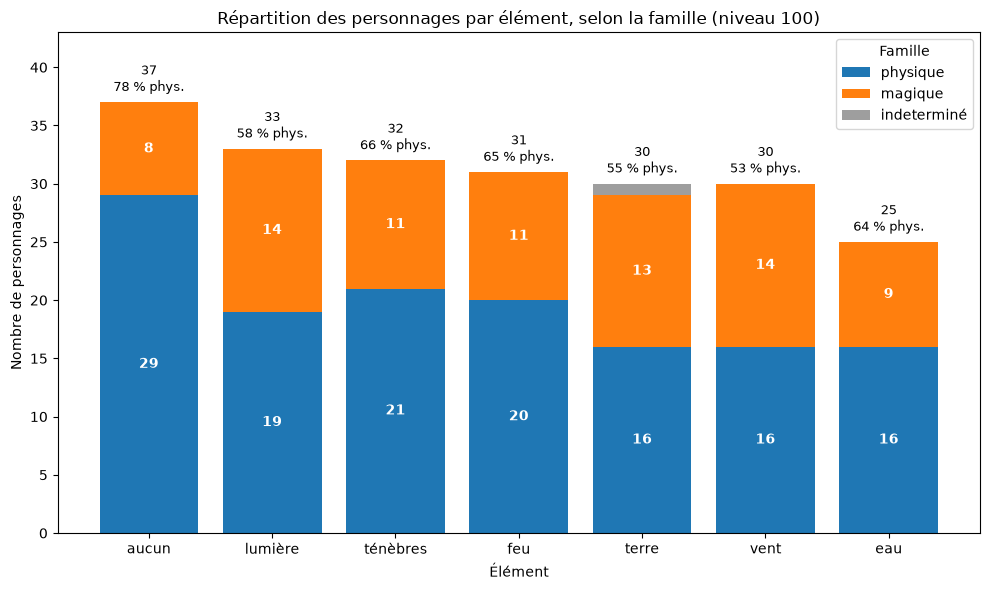

In [35]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]
FAMILLES = ["physique", "magique", "indetermine"]
COULEURS = {"physique": "#1f77b4", "magique": "#ff7f0e", "indetermine": "#9e9e9e"}

ELEMENTS = [r["element"] for r in
            df_perso_100.groupBy("element").count().orderBy(F.desc("count"), "element").collect()]

df_perso_100 = df_perso_100.withColumn(
    "faible_partout", (F.col("ATK") < 2300) & (F.col("MATK") < 2300)
)


tab = (
    df_perso_100.groupBy("element")
    .pivot("famille", FAMILLES).count().na.fill(0)
    .withColumn("total", F.col("physique") + F.col("magique") + F.col("indetermine"))
    .toPandas().set_index("element").loc[ELEMENTS]
)


fig, ax = plt.subplots(figsize=(10, 6))
bas = np.zeros(len(tab))
for fam in FAMILLES:
    ax.bar(tab.index, tab[fam], bottom = bas, color = COULEURS[fam], label=fam.replace("indetermine", "indeterminé"))

    for i, (v, b) in enumerate(zip(tab[fam], bas)):
        if v >= 3:                                  # pas d'étiquette dans un segment minuscule
            ax.text(i, b + v / 2, int(v), ha="center", va="center",
                    color="white", fontsize=10, fontweight="bold")
    bas += tab[fam].values

for i, (el, row) in enumerate(tab.iterrows()):
    pct = row["physique"] / (row["physique"] + row["magique"]) * 100
    ax.text(i, row["total"] + 0.6, f"{int(row['total'])}\n{pct:.0f} % phys.",
            ha="center", va="bottom", fontsize=9)

ax.set_ylim(0, tab["total"].max() + 6)
ax.set_title("Répartition des personnages par élément, selon la famille (niveau 100)")
ax.set_xlabel("Élément")
ax.set_ylabel("Nombre de personnages")
ax.legend(title="Famille")
plt.tight_layout()
plt.show()

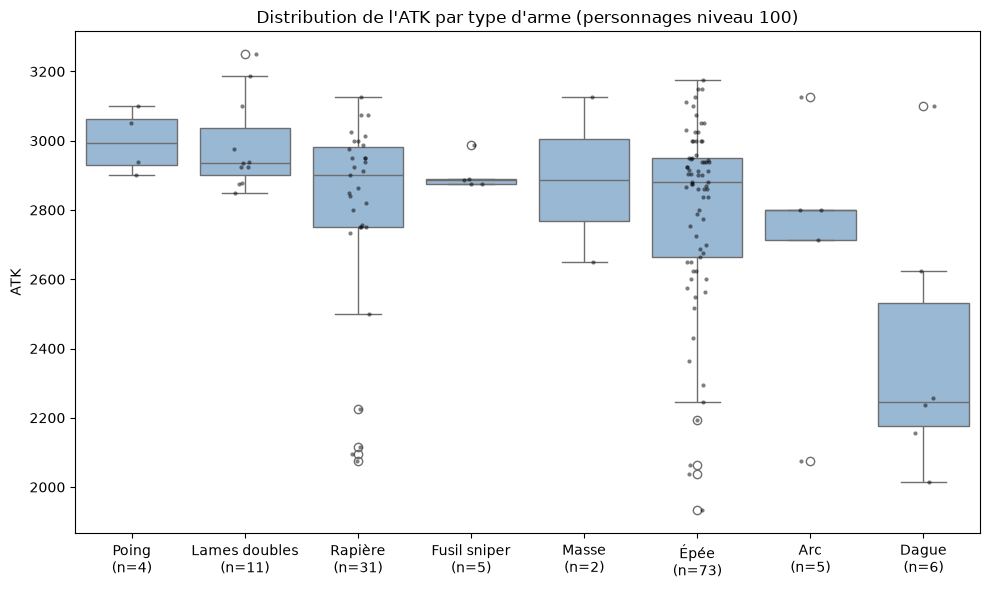

In [10]:
pdf = (
    df_perso_100
    .filter(F.col("famille") == "physique")
    .select("nom", "arme", "ATK")
    .toPandas()
)
ordre = pdf.groupby("arme")["ATK"].median().sort_values(ascending=False).index
effectifs = pdf["arme"].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=pdf, x="arme", y="ATK", order=ordre, ax=ax, color="#8fb8de")
sns.stripplot(data=pdf, x="arme", y="ATK", order=ordre, ax=ax,
              color="black", size=3, alpha=0.5)

ax.set_xticks(range(len(ordre)))
ax.set_xticklabels([f"{a}\n(n={effectifs[a]})" for a in ordre])
ax.set_title("Distribution de l'ATK par type d'arme (personnages niveau 100)")
ax.set_xlabel("")
ax.set_ylabel("ATK")
plt.tight_layout()
plt.show()


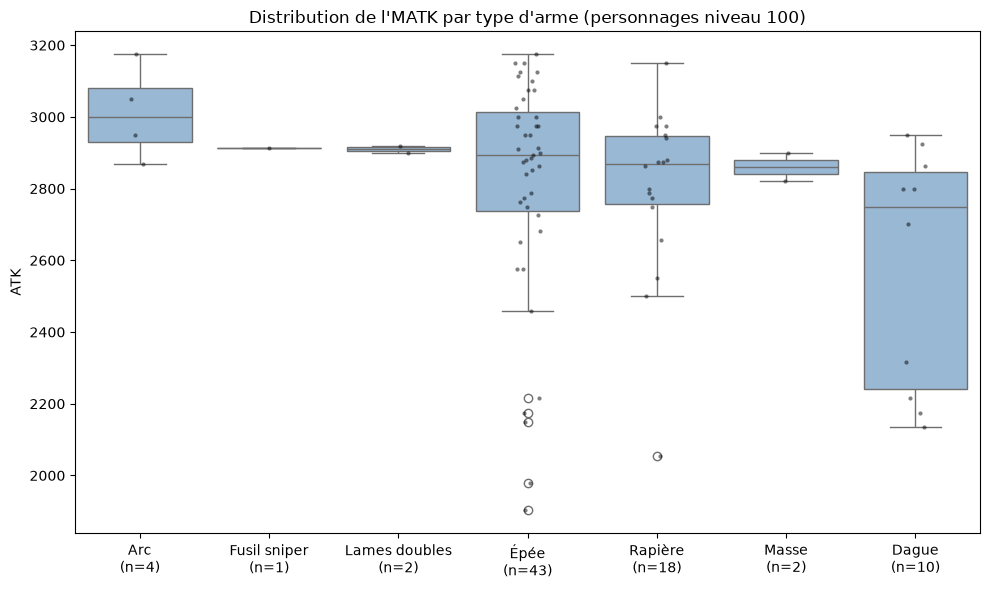

In [11]:
pdf = (
    df_perso_100
    .filter(F.col("famille") == "magique")
    .select("nom", "arme", "MATK")
    .toPandas()
)

ordre = pdf.groupby("arme")["MATK"].median().sort_values(ascending=False).index
effectifs = pdf["arme"].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=pdf, x="arme", y="MATK", order=ordre, ax=ax, color="#8fb8de")
sns.stripplot(data=pdf, x="arme", y="MATK", order=ordre, ax=ax,
              color="black", size=3, alpha=0.5)

ax.set_xticks(range(len(ordre)))
ax.set_xticklabels([f"{a}\n(n={effectifs[a]})" for a in ordre])
ax.set_title("Distribution de l'MATK par type d'arme (personnages niveau 100)")
ax.set_xlabel("")
ax.set_ylabel("ATK")
plt.tight_layout()
plt.show()


### Graphique : Les stats

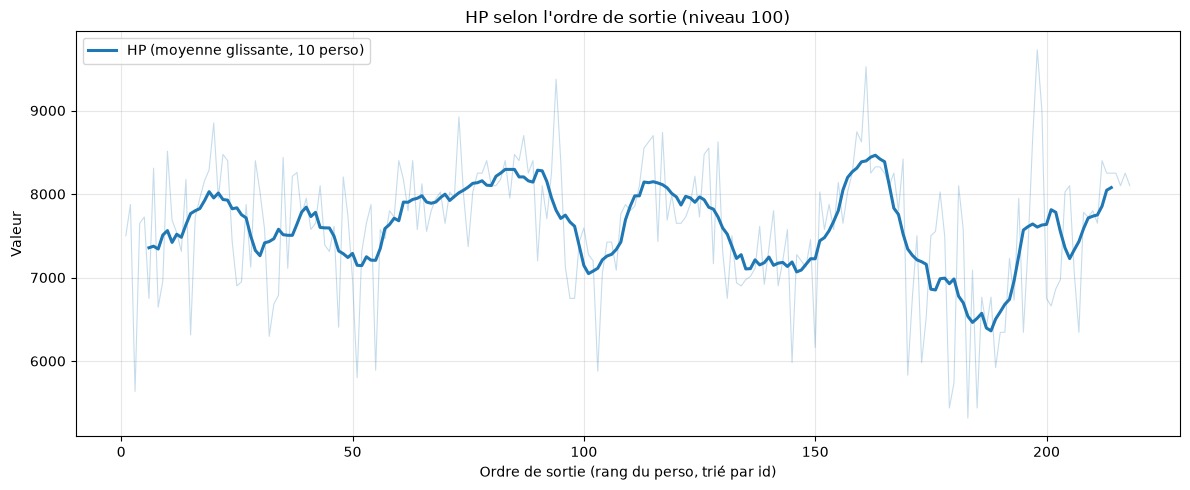

In [12]:
pdf = df_perso_100.select("id", "nom_complet", "HP").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("HP", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("HP selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

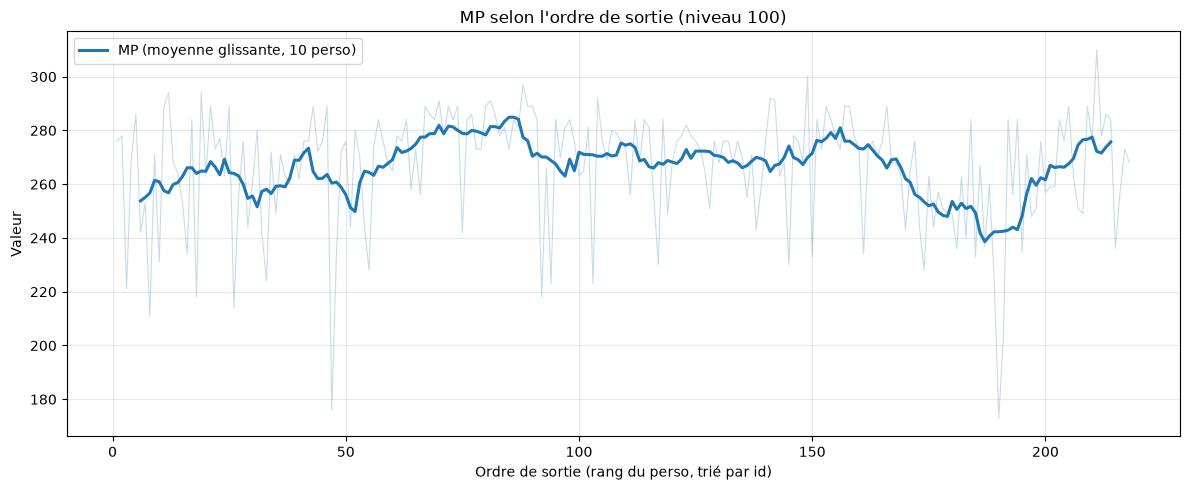

In [13]:
pdf = df_perso_100.select("id", "nom_complet", "MP").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("MP", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("MP selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

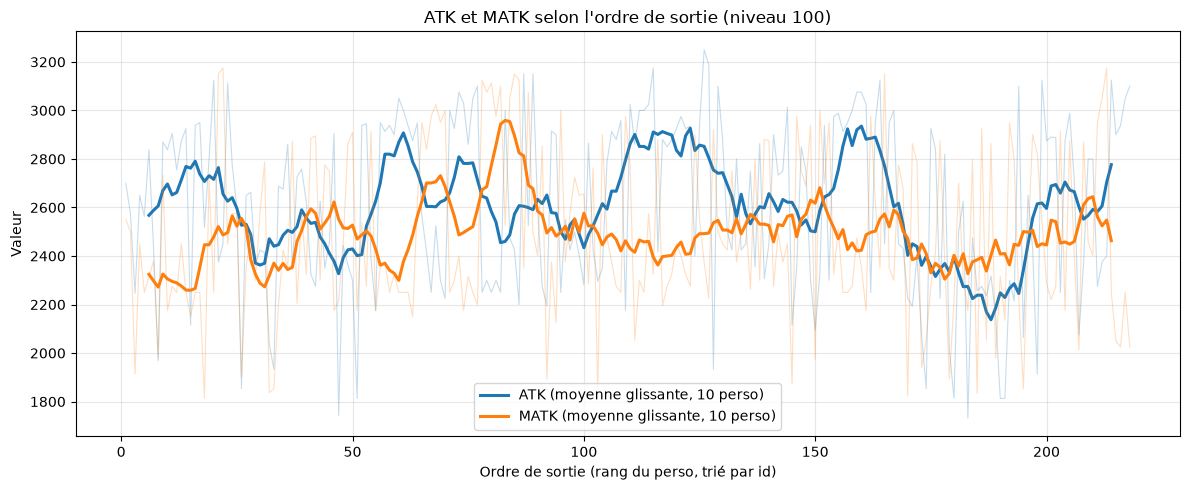

In [14]:
pdf = df_perso_100.select("id", "nom_complet", "ATK", "MATK").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("ATK", "#1f77b4"), ("MATK", "#ff7f0e")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("ATK et MATK selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

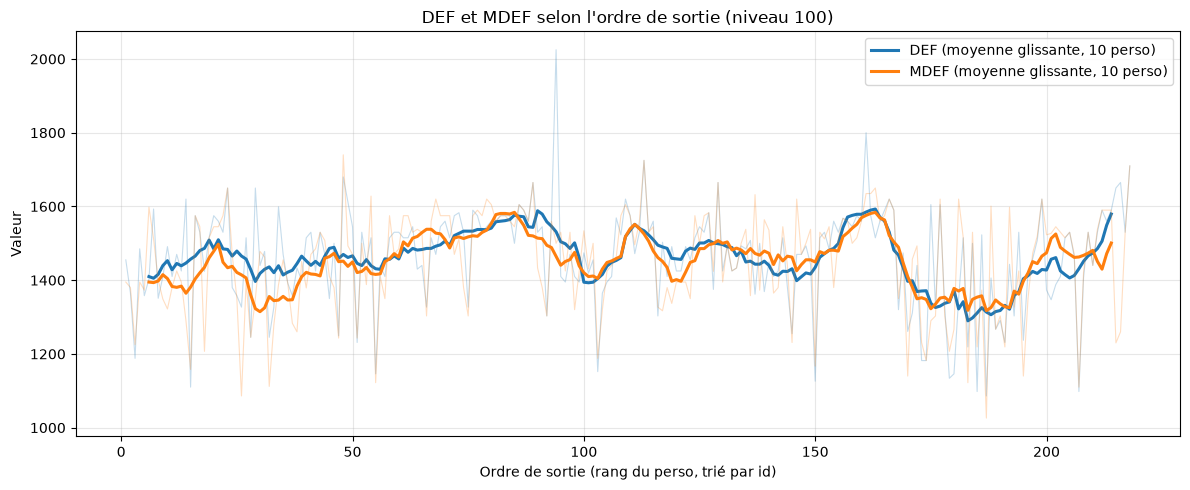

In [15]:
pdf = df_perso_100.select("id", "nom_complet", "DEF", "MDEF").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("DEF", "#1f77b4"), ("MDEF", "#ff7f0e")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("DEF et MDEF selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

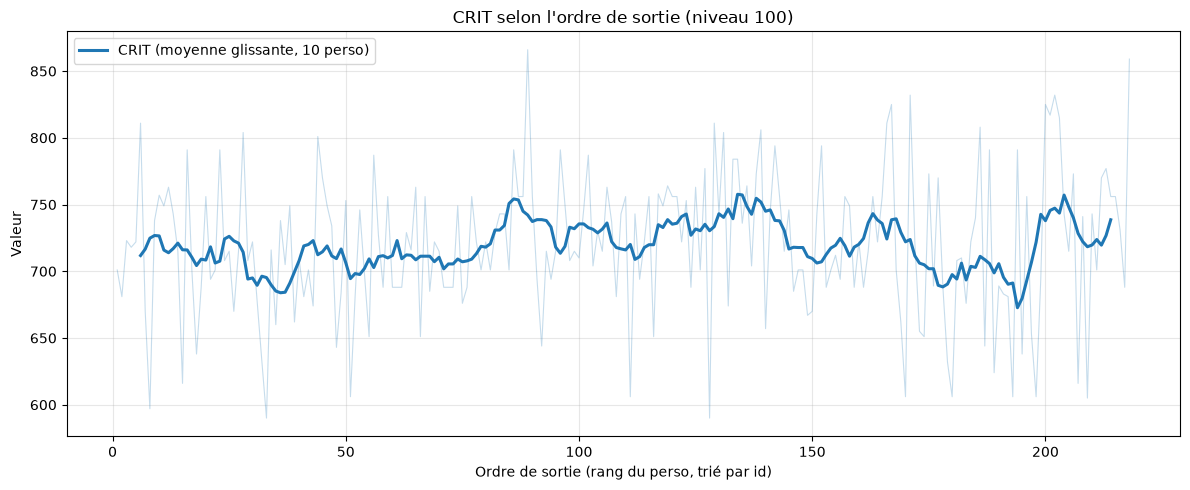

In [16]:
pdf = df_perso_100.select("id", "nom_complet", "CRIT").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("CRIT", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("CRIT selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

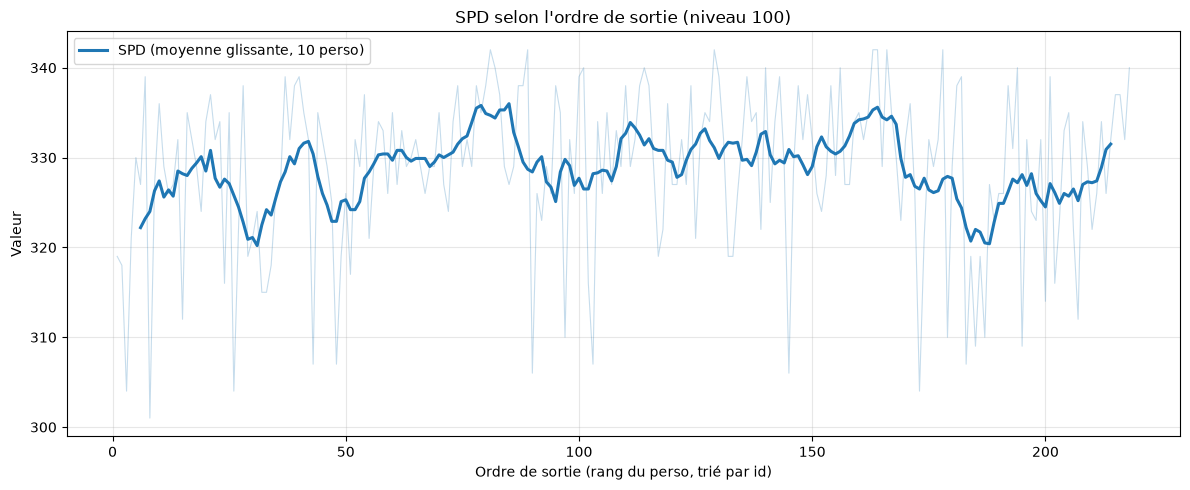

In [17]:
pdf = df_perso_100.select("id", "nom_complet", "SPD").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("SPD", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("SPD selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

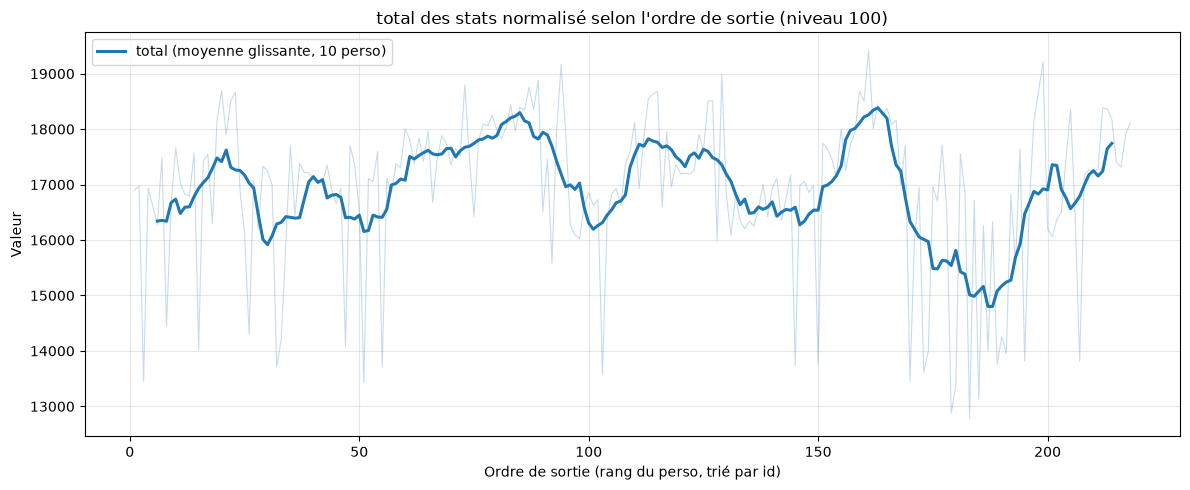



Comme les HP représente environ 45% du total des stats, alors on normalise sur le graphique d'après



In [18]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT" ,"SPD"]

df_total = df_perso_100.withColumn("total" , sum(F.col(i) for i in STATS))


pdf = df_total.select("id", "nom_complet", "total").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("total", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("total des stats normalisé selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n\nComme les HP représente environ 45% du total des stats, alors on normalise sur le graphique d'après\n")

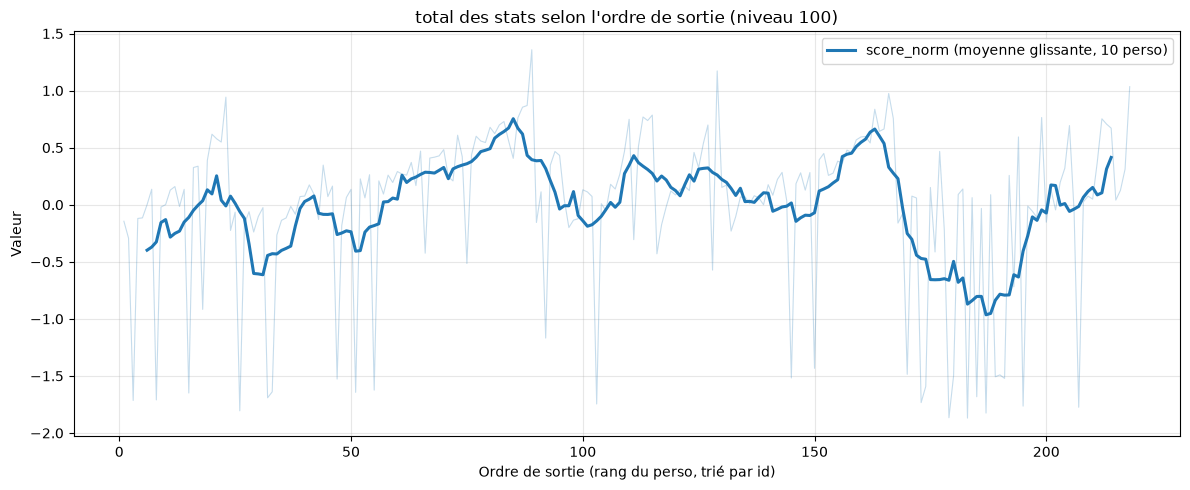

In [19]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT" ,"SPD"]

ms = df_perso_100.agg(
    *[F.avg(s).alias(f"{s}_moy") for s in STATS],
    *[F.stddev(s).alias(f"{s}_std") for s in STATS],
).first().asDict()

df_total = (
    df_perso_100
    .withColumn("total", sum(F.col(s) for s in STATS))
    .withColumn("score_norm",
        sum((F.col(s) - ms[f"{s}_moy"]) / ms[f"{s}_std"] for s in STATS) / len(STATS))
)

pdf = df_total.select("id", "nom_complet", "score_norm").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("score_norm", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("total des stats selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

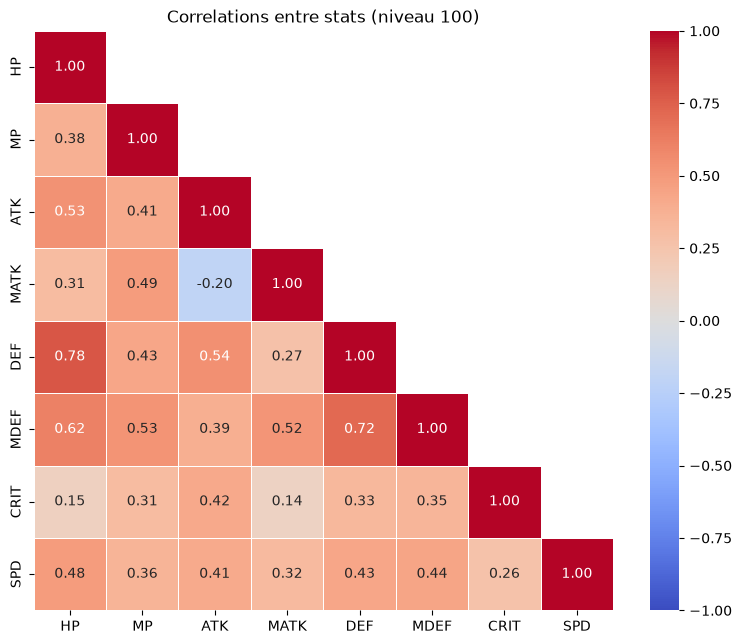

=== Paires classé ===


,stat_1,stat_2,r
6,DEF,HP,0.783372
14,MDEF,DEF,0.718355
10,MDEF,HP,0.615044
8,DEF,ATK,0.543190
1,ATK,HP,0.532094
11,MDEF,MP,0.527338
13,MDEF,MATK,0.517358
4,MATK,MP,0.489912
21,SPD,HP,0.484790
26,SPD,MDEF,0.438793


In [28]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def matrice_correlation(df, cols):
    paires = list(combinations(cols, 2))
    ligne = df.agg(*[F.corr(a, b).alias(f"{a}__{b}") for a, b in paires]).first()
    mat = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for a, b in paires:
        mat.loc[a, b] = mat.loc[b, a] = ligne[f"{a}__{b}"]
    return mat

corr = matrice_correlation(df_perso_100, STATS)

fig, ax = plt.subplots(figsize=(8, 6.5))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm", vmin = -1, vmax=1, center = 0, square = True, linewidths=0.5, ax= ax)
ax.set_title("Correlations entre stats (niveau 100)")
plt.tight_layout()
plt.show()

print("=== Paires classé ===")
triangle = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
paires = triangle.stack().rename("r").reset_index()
paires.columns = ["stat_1", "stat_2", "r"]
paires.sort_values("r", key=abs, ascending=False)

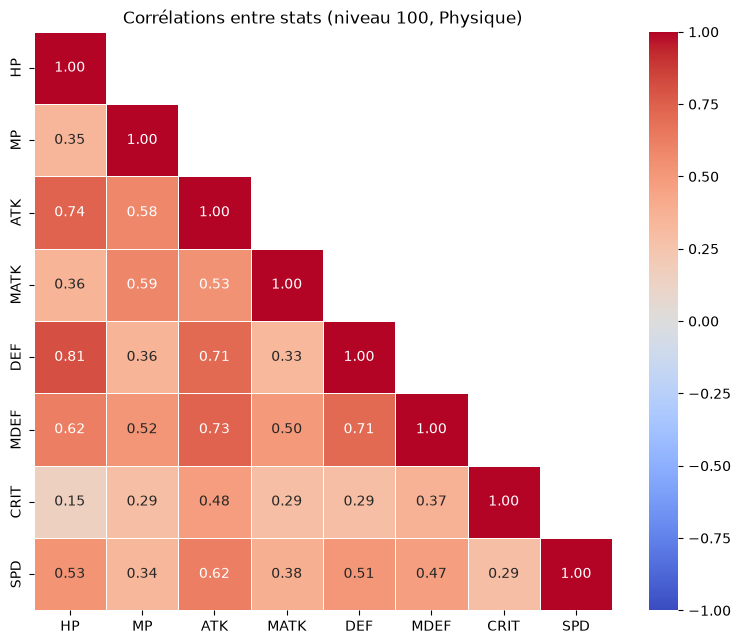

,stat_1,stat_2,r
6,DEF,HP,0.812464
1,ATK,HP,0.735340
12,MDEF,ATK,0.734913
8,DEF,ATK,0.711152
14,MDEF,DEF,0.710994
10,MDEF,HP,0.621900
23,SPD,ATK,0.619933
4,MATK,MP,0.591292
2,ATK,MP,0.582662
5,MATK,ATK,0.533137


In [21]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]


corr = matrice_correlation(df_perso_100.filter(F.col("famille") == "physique"), STATS)

# Heatmap (triangle du bas seulement : la matrice est symétrique)
fig, ax = plt.subplots(figsize=(8, 6.5))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Corrélations entre stats (niveau 100, Physique)")
plt.tight_layout()
plt.show()

# Les paires classées, pour lire les chiffres sans la couleur
triangle = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
paires = triangle.stack().rename("r").reset_index()
paires.columns = ["stat_1", "stat_2", "r"]
paires.sort_values("r", key=abs, ascending=False)

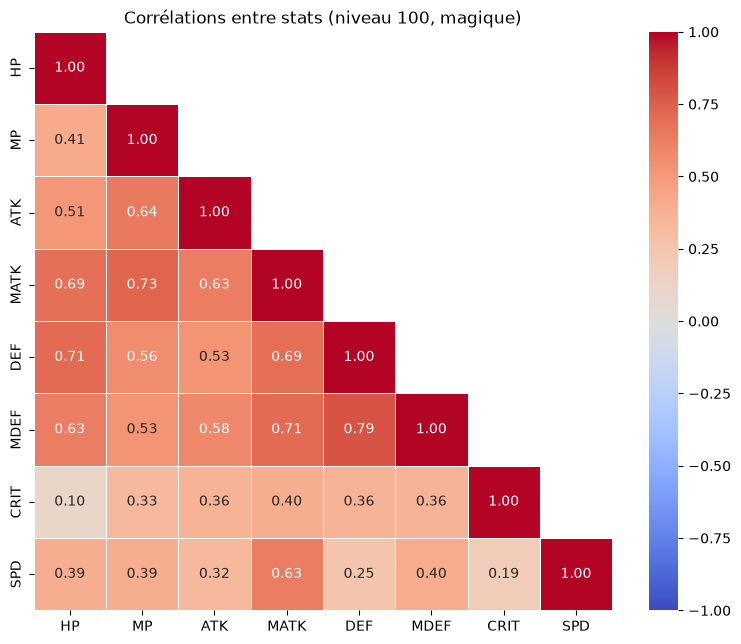

,stat_1,stat_2,r
14,MDEF,DEF,0.793625
4,MATK,MP,0.732303
13,MDEF,MATK,0.709808
6,DEF,HP,0.705460
9,DEF,MATK,0.694547
3,MATK,HP,0.687414
2,ATK,MP,0.641487
5,MATK,ATK,0.631977
10,MDEF,HP,0.629614
24,SPD,MATK,0.629130


In [22]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

corr = matrice_correlation(df_perso_100.filter(F.col("famille") == "magique"), STATS)

# Heatmap (triangle du bas seulement : la matrice est symétrique)
fig, ax = plt.subplots(figsize=(8, 6.5))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Corrélations entre stats (niveau 100, magique)")
plt.tight_layout()
plt.show()

# Les paires classées, pour lire les chiffres sans la couleur
triangle = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
paires = triangle.stack().rename("r").reset_index()
paires.columns = ["stat_1", "stat_2", "r"]
paires.sort_values("r", key=abs, ascending=False)

In [ ]:
print("=== Pas de corrélation entre les élément et les stats ===")


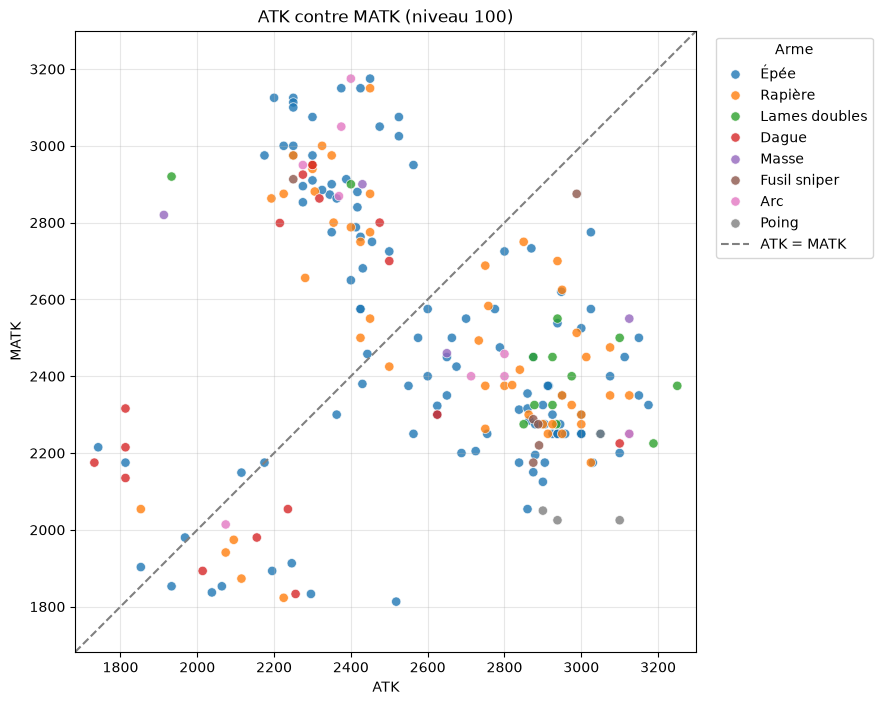

In [30]:
pdf = df_perso_100.select("nom_complet", "arme", "famille", "ATK", "MATK").toPandas()

fig, ax = plt.subplots(figsize=(8.5, 8))
sns.scatterplot(data=pdf, x="ATK", y = "MATK",hue = "arme",  ax = ax, s=45, alpha = 0.8, palette="tab10")

bas = pdf[["ATK", "MATK"]].min().min() - 50
haut = pdf[["ATK", "MATK"]].max().max() + 50
ax.plot([bas, haut], [bas, haut], linestyle="--", color="grey", label="ATK = MATK")

ax.set_xlim(bas, haut); ax.set_ylim(bas, haut)
ax.set_aspect("equal")                       # axes à la même échelle
ax.set_title("ATK contre MATK (niveau 100)")
ax.grid(alpha=0.3)
ax.legend(title="Arme", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Top 5 des meilleur et pire

In [24]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def top_5(df, stat, n=5):
    seuil_haut = (
        df.orderBy(F.desc(stat))
        .limit(n)
        .agg(F.min(stat))
        .first()[0]
    )

    seuil_bas = (
        df.orderBy(F.asc(stat))
        .limit(n)
        .agg(F.max(stat))
        .first()[0]
    )

    top = (
        df.filter(F.col(stat) >= seuil_haut)
        .select("nom_complet", F.col(stat).alias("valeur"))
        .orderBy(F.desc("valeur"), "nom_complet")
    )

    bot = (
        df.filter(F.col(stat) <= seuil_bas)
        .select("nom_complet", F.col(stat).alias("valeur"))
        .orderBy(F.asc("valeur"), "nom_complet")
    )

    return top, bot



for s in STATS:
    top, bot = top_5(df_perso_100, s)
    print(f"=== {s} : meilleur ===");   top.show(truncate=False)
    print(f"=== {s} : pires ===");  bot.show(truncate=False)
    print("--------------------------------------------------------\n")

=== HP : meilleur ===
+---------------------------------------------------+------+
|nom_complet                                        |valeur|
+---------------------------------------------------+------+
|[L'heure de fêter le Nouvel An] Lisbeth            |9728  |
|[Sous le ciel neigeux, les souvenirs] Administrator|9525  |
|[Le Chevalier aux bras de fer] Entokia             |9375  |
|[L'inébranlable Master Macer] Lisbeth              |9000  |
|[La déesse des abîmes] Eydis                       |8925  |
+---------------------------------------------------+------+

=== HP : pires ===
+----------------------------------------+------+
|nom_complet                             |valeur|
+----------------------------------------+------+
|[Le style qui me ressemble] Selka       |5317  |
|[La jeune fille du matin brumeux] Yui   |5438  |
|[Le style Serult d'une enfant] Soltirina|5438  |
|[L'éveil du héros] Kirito               |5637  |
|[Un souvenir d'enfance] Alice           |5740  |
+--------